# UTS Machine Learning — Jalur C (Clustering)
**Nama:** Achyar Yanizar | **NIM:** 2301010543 | **Kelas:** XX

---

## 1. Pemahaman Masalah dan Data

### Tujuan Analisis, Pengguna Hasil, dan Keputusan yang Terbantu
* **Tujuan Analisis:** Mengelompokkan destinasi wisata di Indonesia berdasarkan karakteristik harga tiket masuk, penilaian pengunjung (*rating*), dan estimasi durasi kunjungan menggunakan algoritma *K-Means Clustering*.
* **Pengguna Hasil:** Biro perjalanan (*travel agent*), pengelola destinasi wisata, serta dinas pariwisata daerah.
* **Keputusan yang Terbantu:**
  1. Penyusunan paket tur yang sesuai dengan anggaran dan waktu luang wisatawan (misalnya paket wisata murah singkat vs paket wisata keluarga seharian).
  2. Evaluasi penetapan harga tiket masuk dan peningkatan kualitas fasilitas destinasi berdasarkan perbandingan *rating* dan durasi kunjungan tiap kelompok.

## Informasi Dataset & Cara Mengunduh
* **Judul Dataset:** Indonesia Tourism Destination (`tourism_with_id.csv`)
* **Sumber Data:** [Kaggle - Indonesia Tourism Destination](https://www.kaggle.com/datasets/aprabowo/indonesia-tourism-destination)
* **Lisensi:** Data files © Original Authors

| Nama Kolom | Tipe Data | Arti Kolom | Satuan |
| :--- | :--- | :--- | :--- |
| `Place_Name` | Kategorikal (`object`) | Nama objek/destinasi wisata (sebagai identitas referensi) | Teks |
| `Category` | Kategorikal (`object`) | Kategori wisata (Budaya, Taman Hiburan, Cagar Alam, Bahari, dll.) | Teks |
| `Price` | Numerik (`int64`) | Harga tiket masuk destinasi wisata | Rupiah (IDR) |
| `Rating` | Numerik (`float64`) | Skor penilaian rata-rata dari pengunjung | Skala 1,0 – 5,0 |
| `Time_Minutes` | Numerik (`float64`) | Estimasi lama waktu kunjungan di lokasi wisata | Menit |

In [15]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
import matplotlib.cm as cm

# Tetapkan SEED dari 3 digit terakhir NIM (2301010543)
SEED = 543
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
os.makedirs("reports", exist_ok=True)

# Memuat dataset
file_path = "tourism_with_id.csv"
if not os.path.exists(file_path):
    file_path = "../data/tourism_with_id.csv"

df = pd.read_csv(file_path)
# Menghapus kolom indeks kosong bawaan CSV jika ada (seperti Unnamed: 11)
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

print(f"Jumlah baris: {df.shape[0]}, Jumlah kolom: {df.shape[1]}")
fitur_numerik = ["Price", "Rating", "Time_Minutes"]

display(df[["Place_Name", "Category", "City"] + fitur_numerik].head())
display(df[fitur_numerik].describe().T.round(2))

Jumlah baris: 437, Jumlah kolom: 11


,Place_Name,Category,City,Price,Rating,Time_Minutes
0,Monumen Nasional,Budaya,Jakarta,20000,4.6,15.0
1,Kota Tua,Budaya,Jakarta,0,4.6,90.0
2,Dunia Fantasi,Taman Hiburan,Jakarta,270000,4.6,360.0
3,Taman Mini Indonesia Indah (TMII),Taman Hiburan,Jakarta,10000,4.5,NaN
4,Atlantis Water Adventure,Taman Hiburan,Jakarta,94000,4.5,60.0


,count,mean,std,min,25%,50%,75%,max
Price,437.0,24652.17,66446.37,0.0,0.0,5000.0,20000.0,900000.0
Rating,437.0,4.44,0.21,3.4,4.3,4.5,4.6,5.0
Time_Minutes,205.0,82.61,52.87,10.0,45.0,60.0,120.0,360.0


### Keputusan saya
Saya menggunakan file `tourism_with_id.csv` yang memiliki 437 destinasi wisata dan memilih 3 fitur numerik inti (`Price`, `Rating`, dan `Time_Minutes`) untuk pemodelan *clustering*. Ketiga fitur ini memenuhi syarat minimal dataset (lebih dari 200 baris dan minimal 3 fitur numerik) serta langsung menggambarkan aspek biaya, kualitas kepuasan, dan kebutuhan waktu kunjungan wisata. Kolom koordinat (`Lat`, `Long`) tidak dimasukkan agar pengelompokan murni berdasarkan karakteristik pengalaman wisata, bukan letak geografis kota.

## 2. Eksplorasi dan Visualisasi Data

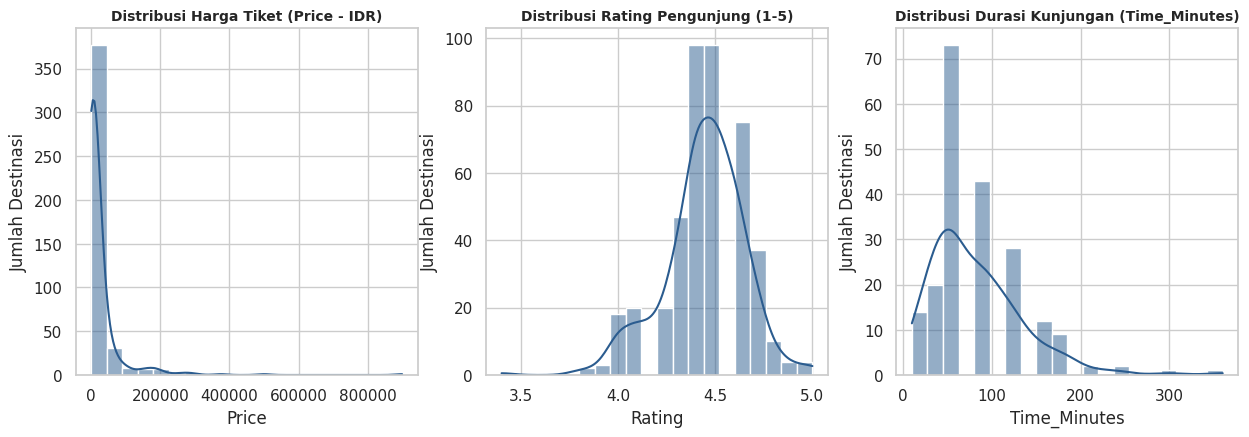

In [16]:
# Grafik 1: Distribusi Fitur (Histogram + KDE)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
label_fitur = ["Harga Tiket (Price - IDR)", "Rating Pengunjung (1-5)", "Durasi Kunjungan (Time_Minutes)"]

for ax, col, title in zip(axes, fitur_numerik, label_fitur):
    sns.histplot(df[col].dropna(), kde=True, bins=20, color="#2b5c8f", ax=ax)
    ax.set_title(f"Distribusi {title}", fontsize=10, fontweight="bold")
    ax.set_xlabel(col)
    ax.set_ylabel("Jumlah Destinasi")

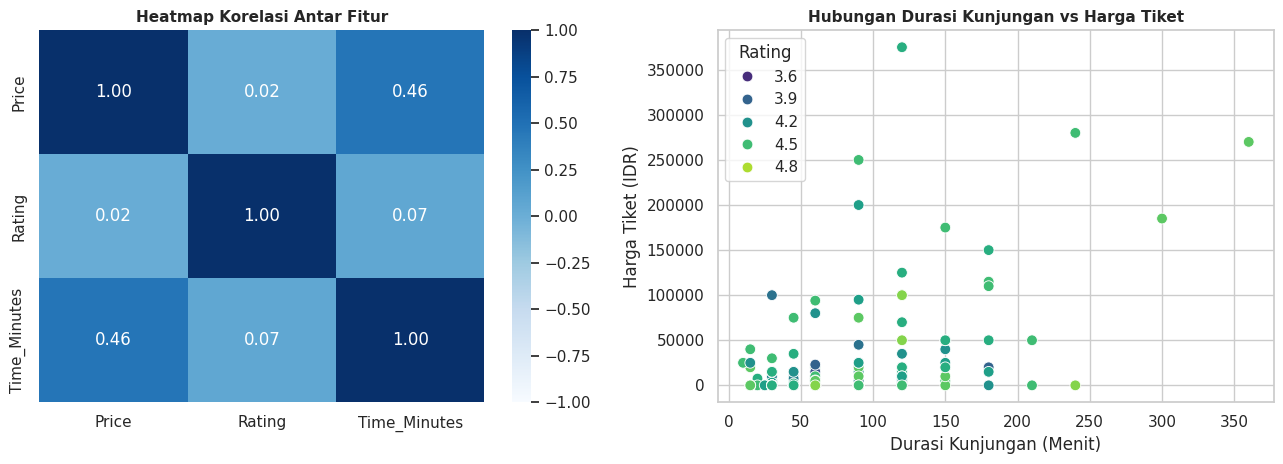

In [17]:
# Grafik 2: Hubungan Antar Fitur (Heatmap Korelasi & Scatter Plot)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.heatmap(df[fitur_numerik].corr(), annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Heatmap Korelasi Antar Fitur", fontsize=11, fontweight="bold")

sns.scatterplot(data=df, x="Time_Minutes", y="Price", hue="Rating", palette="viridis", s=60, ax=axes[1])
axes[1].set_title("Hubungan Durasi Kunjungan vs Harga Tiket", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Durasi Kunjungan (Menit)")
axes[1].set_ylabel("Harga Tiket (IDR)")

plt.tight_layout()
plt.savefig("reports/02_hubungan_antar_fitur.png", dpi=150)
plt.show()

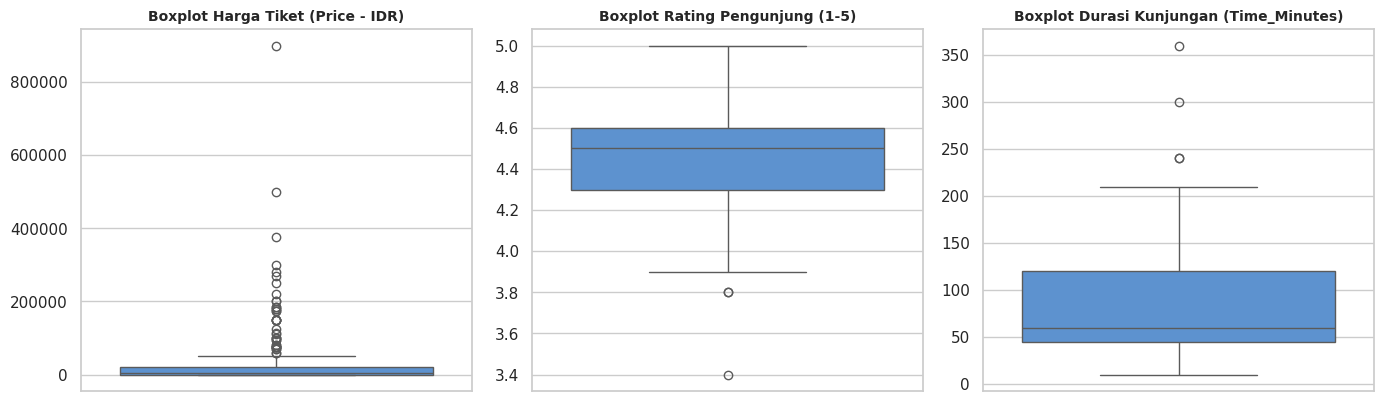

In [18]:
# Grafik 3: Boxplot untuk Melihat Outlier
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, col, title in zip(axes, fitur_numerik, label_fitur):
    sns.boxplot(y=df[col], color="#4a90e2", ax=ax)
    ax.set_title(f"Boxplot {title}", fontsize=10, fontweight="bold")
    ax.set_ylabel("")

plt.tight_layout()
plt.savefig("reports/03_boxplot_outlier.png", dpi=150)
plt.show()

**Interpretasi Grafik 1 (Distribusi Fitur):**
Distribusi `Price` sangat menceng ke kanan (*right-skewed*) karena banyak destinasi wisata alam/budaya berharga murah atau gratis (`Rp0`), sementara sebagian kecil taman hiburan mematok harga tinggi. Sementara itu, `Rating` terkonsentrasi tinggi di rentang `4,3` hingga `4,7`.

**Interpretasi Grafik 2 (Hubungan Antar Fitur):**
`Time_Minutes` dan `Price` memiliki korelasi positif sedang, yang berarti destinasi berdurasi kunjungan lama cenderung memiliki tarif tiket lebih mahal. Di sisi lain, `Rating` hampir tidak berkorelasi dengan harga, menandakan destinasi murah sekalipun dapat memperoleh penilaian tinggi.

**Interpretasi Grafik 3 (Boxplot Outlier):**
Terdeteksi sejumlah pencilan (*outlier*) di atas batas atas pada `Price` (tiket di atas Rp100.000 seperti taman rekreasi besar) dan `Time_Minutes` (kunjungan di atas 180 menit), serta beberapa *outlier* bawah pada `Rating`.

### Keputusan saya
Dari eksplorasi data terlihat adanya perbedaan satuan yang sangat besar antara `Price` (puluhan hingga ratusan ribu rupiah) dengan `Rating` (skala 1–5) dan `Time_Minutes` (puluhan menit), sehingga proses *scaling* wajib diterapkan. Selain itu, ditemukan nilai kosong (*missing value*) pada kolom `Time_Minutes` yang perlu ditangani pada tahap pra-pemrosesan.

## 3. Pra-pemrosesan Data

In [19]:
df_prep = df[["Place_Name", "Category", "City"] + fitur_numerik].copy()

# 1. Cek Missing Value dan Duplikat
print("Missing value sebelum ditangani:\n", df_prep[fitur_numerik].isnull().sum())
print("\nJumlah baris duplikat:", df_prep.duplicated().sum())

# Imputasi missing value pada Time_Minutes menggunakan median per Category (lalu median global jika masih ada)
df_prep["Time_Minutes"] = df_prep["Time_Minutes"].fillna(
    df_prep.groupby("Category")["Time_Minutes"].transform("median")
)
df_prep["Time_Minutes"] = df_prep["Time_Minutes"].fillna(df_prep["Time_Minutes"].median())
print("\nMissing value setelah imputasi:\n", df_prep[fitur_numerik].isnull().sum())

# 2. Cek Konsistensi Kategori
print("\nKategori wisata unik:", df_prep["Category"].unique())

# 3. Cek Outlier menggunakan metode IQR
Q1 = df_prep[fitur_numerik].quantile(0.25)
Q3 = df_prep[fitur_numerik].quantile(0.75)
IQR = Q3 - Q1
outliers = ((df_prep[fitur_numerik] < (Q1 - 1.5 * IQR)) | (df_prep[fitur_numerik] > (Q3 + 1.5 * IQR))).sum()
print("\nJumlah outlier terdeteksi (metode IQR):\n", outliers)

# 4. Scaling menggunakan StandardScaler (tanpa train-test split sesuai aturan Jalur C)
X_raw = df_prep[fitur_numerik].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

df_scaled = pd.DataFrame(X_scaled, columns=fitur_numerik)
display(df_scaled.describe().T[["mean", "std", "min", "max"]].round(3))

Missing value sebelum ditangani:
 Price             0
Rating            0
Time_Minutes    232
dtype: int64

Jumlah baris duplikat: 0

Missing value setelah imputasi:
 Price           0
Rating          0
Time_Minutes    0
dtype: int64

Kategori wisata unik: ['Budaya' 'Taman Hiburan' 'Cagar Alam' 'Bahari' 'Pusat Perbelanjaan'
 'Tempat Ibadah']

Jumlah outlier terdeteksi (metode IQR):
 Price           40
Rating           3
Time_Minutes    28
dtype: int64


,mean,std,min,max
Price,-0.0,1.001,-0.371,13.189
Rating,-0.0,1.001,-5.005,2.674
Time_Minutes,0.0,1.001,-1.757,7.440


### Keputusan saya
1. **Penanganan Missing Value:** Kolom `Time_Minutes` memiliki nilai kosong yang saya isi (*imputasi*) menggunakan **nilai median berdasarkan kategori wisata (`Category`)**. Median dipilih karena distribusi durasi kunjungan menceng dan tahan terhadap *outlier*, sekaligus menjaga jumlah baris tetap 437 destinasi (tidak berkurang di bawah syarat minimal 200 baris).
2. **Duplikat & Kategori:** Tidak ditemukan baris duplikat (`0`), dan penulisan nama kategori pada `Category` sudah konsisten tanpa salah ketik.
3. **Penanganan Outlier (IQR):** Pencilan pada `Price` dan `Time_Minutes` tetap dipertahankan karena merepresentasikan segmen nyata destinasi wisata premium/taman hiburan berskala besar yang penting untuk dipisahkan sebagai segmen tersendiri.
4. **Tanpa Train-Test Split & Wajib Scaling:** Sesuai aturan Jalur C, seluruh data diproses tanpa pemisahan latih-uji dan distandarisasi menggunakan `StandardScaler` agar jarak Euclidean tidak didominasi oleh variabel `Price`.

## 4. Pemodelan (K-Means: Tanpa Scaling vs Dengan Scaling)

,k,Inertia_Tanpa_Scaling,Silhouette_Tanpa_Scaling,Inertia_Dengan_Scaling,Silhouette_Dengan_Scaling
0,2,7.689554e+11,0.8919,1003.20,0.5318
1,3,3.179239e+11,0.8689,762.01,0.3315
2,4,1.857986e+11,0.8480,599.43,0.3746
3,5,9.624905e+10,0.7797,506.27,0.2965
4,6,6.305294e+10,0.7644,428.32,0.3379
5,7,3.919374e+10,0.7349,342.62,0.3664
6,8,2.860541e+10,0.6878,286.03,0.3675


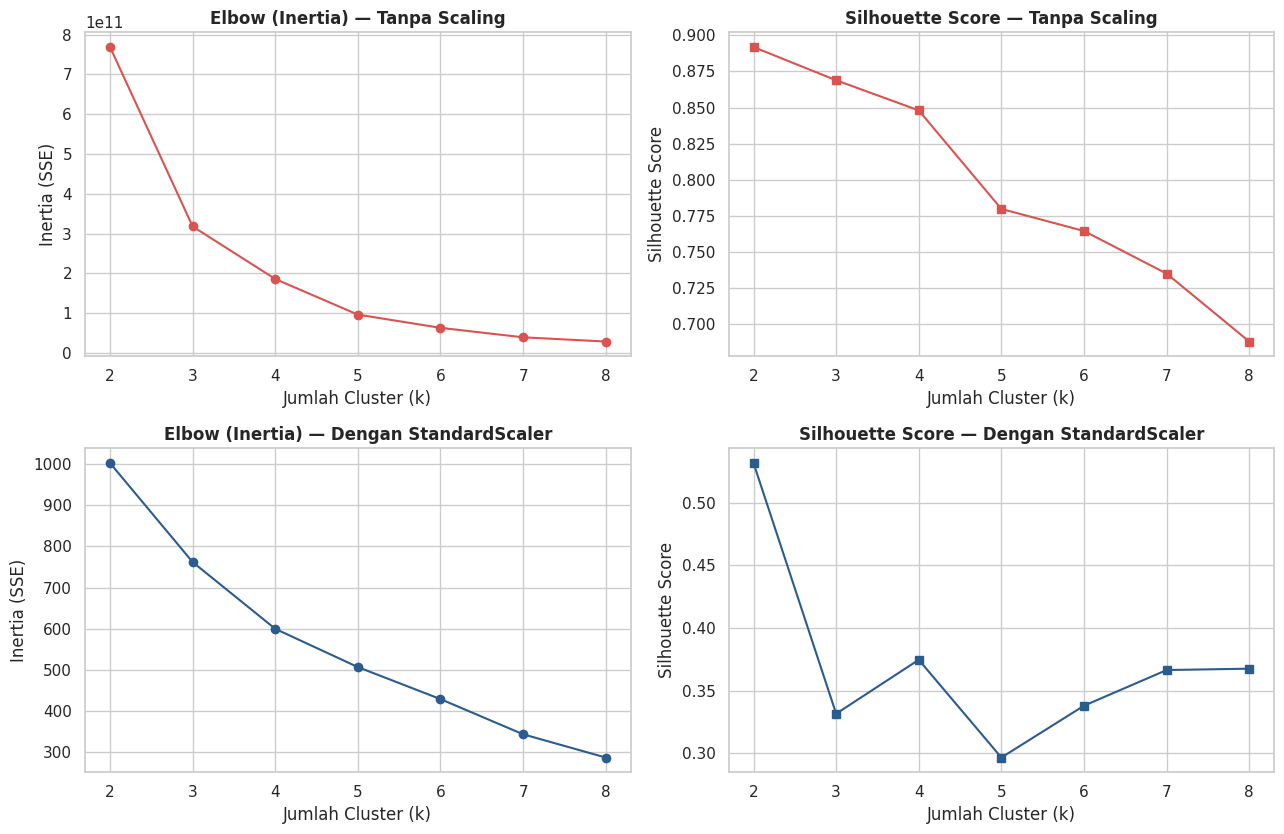

In [20]:
hasil_k = []

for k in range(2, 9):
    # Tanpa scaling
    km_raw = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    lbl_raw = km_raw.fit_predict(X_raw)
    sil_raw = silhouette_score(X_raw, lbl_raw)

    # Dengan scaling
    km_scaled = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    lbl_scaled = km_scaled.fit_predict(X_scaled)
    sil_scaled = silhouette_score(X_scaled, lbl_scaled)

    hasil_k.append({
        "k": k,
        "Inertia_Tanpa_Scaling": round(km_raw.inertia_, 2),
        "Silhouette_Tanpa_Scaling": round(sil_raw, 4),
        "Inertia_Dengan_Scaling": round(km_scaled.inertia_, 2),
        "Silhouette_Dengan_Scaling": round(sil_scaled, 4)
    })

df_hasil_k = pd.DataFrame(hasil_k)
display(df_hasil_k)

# Grafik Perbandingan Elbow dan Silhouette
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

axes[0, 0].plot(df_hasil_k["k"], df_hasil_k["Inertia_Tanpa_Scaling"], marker="o", color="#d9534f")
axes[0, 0].set_title("Elbow (Inertia) — Tanpa Scaling", fontweight="bold")
axes[0, 0].set_xlabel("Jumlah Cluster (k)")
axes[0, 0].set_ylabel("Inertia (SSE)")

axes[0, 1].plot(df_hasil_k["k"], df_hasil_k["Silhouette_Tanpa_Scaling"], marker="s", color="#d9534f")
axes[0, 1].set_title("Silhouette Score — Tanpa Scaling", fontweight="bold")
axes[0, 1].set_xlabel("Jumlah Cluster (k)")
axes[0, 1].set_ylabel("Silhouette Score")

axes[1, 0].plot(df_hasil_k["k"], df_hasil_k["Inertia_Dengan_Scaling"], marker="o", color="#2b5c8f")
axes[1, 0].set_title("Elbow (Inertia) — Dengan StandardScaler", fontweight="bold")
axes[1, 0].set_xlabel("Jumlah Cluster (k)")
axes[1, 0].set_ylabel("Inertia (SSE)")

axes[1, 1].plot(df_hasil_k["k"], df_hasil_k["Silhouette_Dengan_Scaling"], marker="s", color="#2b5c8f")
axes[1, 1].set_title("Silhouette Score — Dengan StandardScaler", fontweight="bold")
axes[1, 1].set_xlabel("Jumlah Cluster (k)")
axes[1, 1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.savefig("reports/04_elbow_silhouette_comparison.png", dpi=150)
plt.show()

### Keputusan saya
Perbandingan K-Means pada $k=2$ hingga $8$ (`n_init=10`, `random_state=543`) membuktikan pentingnya *scaling*:
* **Tanpa Scaling:** Nilai *Silhouette Score* tampak tinggi secara semu karena perhitungan jarak sepenuhnya dikuasai oleh `Price` (skala puluhan ribu), sementara `Rating` (skala 1–5) dan `Time_Minutes` terabaikan.
* **Dengan StandardScaler:** Ketiga fitur memiliki kontribusi jarak yang seimbang. Grafik Elbow menunjukkan penurunan *inertia* (SSE) yang tajam hingga **$k = 3$ dan $k = 4$** lalu mulai melandai, sehingga model **dengan scaling** dipilih untuk tahap evaluasi.

## 5. Evaluasi dan Interpretasi Cluster

Total SSE (Inertia) untuk k = 3: 762.01
Silhouette Score untuk k = 3: 0.3315



,Price,Rating,Time_Minutes,Jumlah_Destinasi,Persentase (%)
Cluster,,,,,
0,11664.21,4.55,65.92,271,62.01
1,253500.00,4.49,132.00,20,4.58
2,17410.96,4.24,89.59,146,33.41


Contoh Cluster 0: Monumen Nasional, Kota Tua, Taman Mini Indonesia Indah (TMII)
Contoh Cluster 1: Dunia Fantasi, Pelabuhan Marina, Pulau Tidung
Contoh Cluster 2: Ocean Ecopark, Pulau Pari, Pulau Pramuka


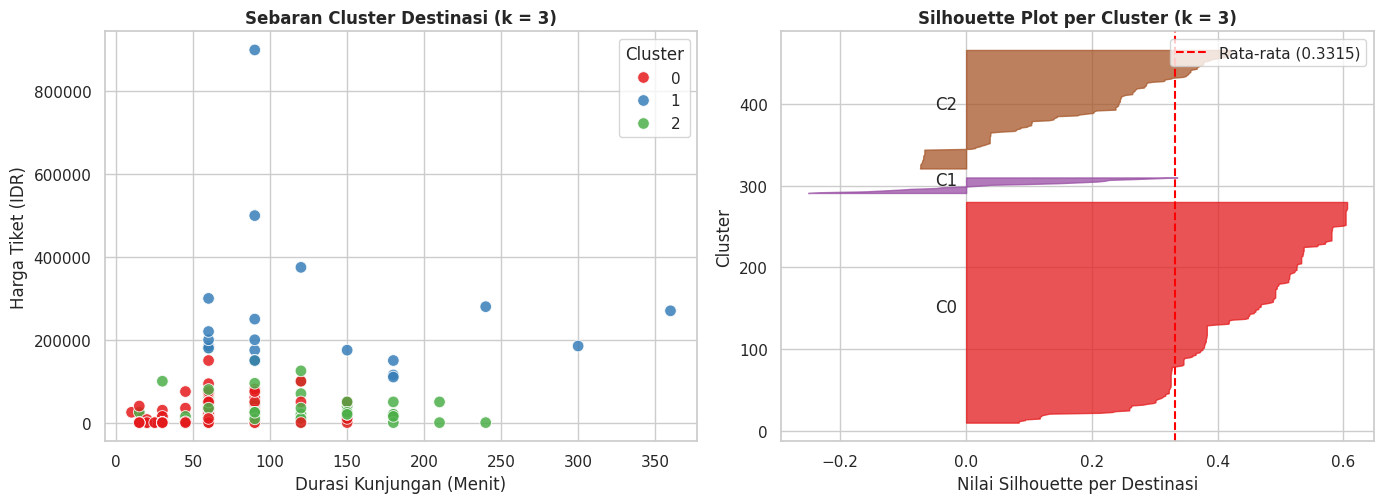

In [21]:
# Ubah nilai k_terpilih di sini jika ingin mencoba k lain (misal 3 atau 4)
k_terpilih = 3
km_final = KMeans(n_clusters=k_terpilih, n_init=10, random_state=SEED)
df_prep["Cluster"] = km_final.fit_predict(X_scaled)

sil_final = silhouette_score(X_scaled, df_prep["Cluster"])
print(f"Total SSE (Inertia) untuk k = {k_terpilih}: {km_final.inertia_:.2f}")
print(f"Silhouette Score untuk k = {k_terpilih}: {sil_final:.4f}\n")

# Tabel Profil Rata-Rata Fitur per Cluster (menggunakan satuan asli)
profil = df_prep.groupby("Cluster")[fitur_numerik].mean().round(2)
profil["Jumlah_Destinasi"] = df_prep["Cluster"].value_counts().sort_index()
profil["Persentase (%)"] = (profil["Jumlah_Destinasi"] / len(df_prep) * 100).round(2)
display(profil)

# Menampilkan contoh 3 destinasi di tiap cluster untuk memudahkan penamaan kelompok
for c in range(k_terpilih):
    contoh = df_prep[df_prep["Cluster"] == c]["Place_Name"].head(3).tolist()
    print(f"Contoh Cluster {c}: {', '.join(contoh)}")

# Visualisasi Scatter Plot 2 Fitur Utama + Silhouette Plot per Sampel
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

sns.scatterplot(
    data=df_prep,
    x="Time_Minutes",
    y="Price",
    hue="Cluster",
    palette="Set1",
    s=70,
    alpha=0.85,
    ax=axes[0]
)
axes[0].set_title(f"Sebaran Cluster Destinasi (k = {k_terpilih})", fontweight="bold")
axes[0].set_xlabel("Durasi Kunjungan (Menit)")
axes[0].set_ylabel("Harga Tiket (IDR)")

# Silhouette Plot per Cluster
sample_sil = silhouette_samples(X_scaled, df_prep["Cluster"])
y_lower = 10
for i in range(k_terpilih):
    ith_sil = np.sort(sample_sil[df_prep["Cluster"] == i])
    y_upper = y_lower + len(ith_sil)
    color = cm.Set1(float(i) / k_terpilih)
    axes[1].fill_betweenx(np.arange(y_lower, y_upper), 0, ith_sil, facecolor=color, edgecolor=color, alpha=0.75)
    axes[1].text(-0.05, y_lower + 0.5 * len(ith_sil), f"C{i}")
    y_lower = y_upper + 10

axes[1].axvline(x=sil_final, color="red", linestyle="--", label=f"Rata-rata ({sil_final:.4f})")
axes[1].set_title(f"Silhouette Plot per Cluster (k = {k_terpilih})", fontweight="bold")
axes[1].set_xlabel("Nilai Silhouette per Destinasi")
axes[1].set_ylabel("Cluster")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.savefig("reports/05_evaluasi_cluster.png", dpi=150)
plt.show()

### Penamaan dan Profil Tiap Kelompok ($k = 3$)
Berdasarkan tabel rata-rata fitur dan contoh destinasi di setiap cluster, ketiga kelompok wisata memiliki karakteristik sebagai berikut:
1. **Cluster 0 — Wisata Populer Hemat & Singkat (271 destinasi / 62,01%):** Kelompok mayoritas dengan tarif tiket paling terjangkau (rata-rata **Rp11.664**), durasi kunjungan paling singkat (**65,92 menit**), dan memiliki *rating* pengunjung tertinggi (**4,55**). Contohnya: *Monumen Nasional, Kota Tua, dan Taman Mini Indonesia Indah (TMII)*.
2. **Cluster 1 — Wisata Premium & Rekreasi Panjang (20 destinasi / 4,58%):** Kelompok destinasi eksklusif dengan harga tiket masuk tertinggi (rata-rata **Rp253.500**) dan durasi kunjungan terlama (**132,00 menit** atau >2 jam), serta tetap menjaga *rating* tinggi (**4,49**). Contohnya: *Dunia Fantasi, Pelabuhan Marina, dan Pulau Tidung*.
3. **Cluster 2 — Wisata Alternatif / Rating Menengah-Rendah (146 destinasi / 33,41%):** Kelompok destinasi berharga ekonomis (rata-rata **Rp17.411**) dengan durasi kunjungan sedang (**89,59 menit**), namun memiliki rata-rata *rating* paling rendah (**4,24**) dibanding kelompok lainnya. Contohnya: *Ocean Ecopark, Pulau Pari, dan Pulau Pramuka*.

### Keputusan saya
* **Pemilihan $k = 3$ (Resolusi Elbow & Silhouette):** Pada grafik pemodelan sebelumnya, penurunan *inertia* (SSE) dengan `StandardScaler` menunjukkan patahan siku (*elbow*) utama pada **$k = 3$** (*Inertia* = **762,01** dan *Silhouette Score* = **0,3315**). Saya memilih $k = 3$ karena mampu memisahkan profil destinasi secara tegas antara wisata murah-singkat favorit (Cluster 0), wisata premium berdurasi lama (Cluster 1), dan wisata ber-*rating* rendah yang perlu dievaluasi (Cluster 2), sekaligus ditunjukkan oleh *Silhouette Plot* di mana mayoritas sampel terutama pada Cluster 0 berada jauh di atas garis rata-rata.
* **Visualisasi:** Saya menggunakan *scatter plot* dua fitur utama (`Time_Minutes` vs `Price`) serta *Silhouette Plot* per cluster untuk memvalidasi kerapatan dan keterpisahan masing-masing segmen secara visual.

## 6. Kesimpulan

### Kelayakan Model dan Pemilihan Jumlah Cluster
Model *K-Means Clustering* dengan pra-pemrosesan `StandardScaler` dinyatakan **layak digunakan** untuk melakukan segmentasi destinasi wisata di Indonesia. Jumlah cluster terpilih adalah **$k = 3$** berdasarkan dua bukti kuantitatif berikut:
1. **Metrik Kerapatan & Keterpisahan (Inertia & Silhouette):** Pada $k = 3$, nilai *Total SSE (Inertia)* turun ke titik siku sebesar **762,01** dengan *Silhouette Score* positif sebesar **0,3315**, menandakan struktur kelompok terbentuk secara stabil setelah seluruh fitur disetarakan skalanya.
2. **Pemisahan Profil Ekonomi dan Kualitas yang Kontras:** Model berhasil membedakan segmen destinasi berbiaya murah dan ber-*rating* tinggi (Cluster 0: rata-rata **Rp11.664**, *rating* **4,55**) dari destinasi premium berdurasi panjang (Cluster 1: rata-rata **Rp253.500**, durasi **132 menit**) serta mendeteksi destinasi dengan skor kepuasan terendah (Cluster 2: *rating* **4,24**).

### Rekomendasi Tindakan Bagi Pengguna (Strategi per Kelompok)
* **Cluster 0 (Wisata Populer Hemat & Singkat):** Biro perjalanan dapat menggabungkan 3–4 destinasi dalam kelompok ini ke dalam satu paket *City Tour Half-Day* berbiaya hemat untuk wisatawan pelajar, keluarga lokal, maupun *backpacker*.
* **Cluster 1 (Wisata Premium & Rekreasi Panjang):** Pengelola destinasi dan agen tur dapat mempromosikan kelompok ini sebagai paket liburan utama akhir pekan (*Full-Day Leisure*) dengan fasilitas tiket terusan (*fast-track*) atau diskon paket rombongan.
* **Cluster 2 (Wisata Alternatif / Rating Menengah-Rendah):** Dinas pariwisata daerah dan pengelola objek wisata perlu memprioritaskan peningkatan kualitas fasilitas, kebersihan kawasan, dan akses transportasi agar *rating* pengunjung (4,24) dapat meningkat setara dengan Cluster 0.

### Keterbatasan dan Saran Perbaikan
* **Keterbatasan:** Pengelompokan hanya menggunakan 3 fitur numerik utama sehingga faktor jumlah ulasan (*popularity*), aksesibilitas jarak antar lokasi, maupun kategori spesifik wisata belum masuk ke dalam perhitungan jarak cluster.
* **Saran Perbaikan:** Pada penelitian selanjutnya, dapat ditambahkan variabel jumlah ulasan pengunjung atau menguji algoritma *DBSCAN* agar destinasi ekstrem berharga sangat tinggi (seperti tiket Rp900.000 pada grafik *scatter*) dapat teridentifikasi sebagai *outlier* tersendiri tanpa menarik posisi *centroid*.

### Keputusan saya
Saya menetapkan **$k = 3$** dengan `StandardScaler` sebagai hasil akhir proyek UTS ini karena memberikan hasil segmentasi yang tajam secara statistik (*Inertia* = 762,01; *Silhouette Score* = 0,3315) serta menghasilkan profil segmen destinasi yang langsung dapat ditindaklanjuti oleh pelaku industri pariwisata.